In [60]:
from sklearn.datasets import load_iris
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score , confusion_matrix, classification_report


datf = load_iris(as_frame = True)
df = datf.frame
print(df.columns)
print(df.head())

Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'target'],
      dtype='object')
   sepal length (cm)  sepal width (cm)  ...  petal width (cm)  target
0                5.1               3.5  ...               0.2       0
1                4.9               3.0  ...               0.2       0
2                4.7               3.2  ...               0.2       0
3                4.6               3.1  ...               0.2       0
4                5.0               3.6  ...               0.2       0

[5 rows x 5 columns]


In [61]:
X = datf.data
y = datf.target
print(X.head())
print(y.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64


In [62]:
X_train , X_test , y_train , y_test = train_test_split( X , y , test_size = 0.2 , random_state = 42)

In [63]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [64]:
kernels = ["linear","poly","rbf"]
accs = []
for i in kernels:
  model = SVC(kernel = i)
  model.fit(X_train, y_train)
  acc = accuracy_score(y_test, model.predict(X_test))
  accs.append(acc)
  print(f"{i} : {acc}")

linear : 0.9666666666666667
poly : 0.9666666666666667
rbf : 1.0


In [67]:
bestind = accs.index(max(accs))
bestk = kernels[bestind]

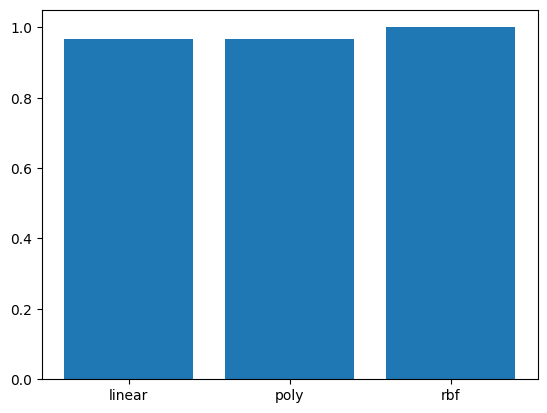

In [66]:
import matplotlib.pyplot as plt
plt.bar(kernels,accs)
plt.show()


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


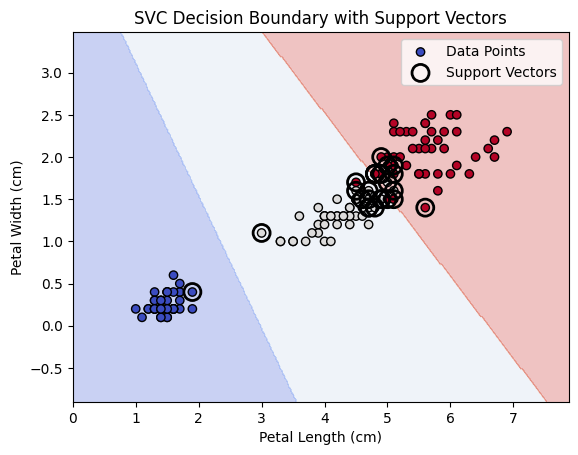

In [75]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC

X = datf.data.iloc[:, 2:4]
y = datf.target

model = SVC(kernel='linear', C=1)
model.fit(X, y)

# Create mesh grid
x_min, x_max = X.iloc[:, 0].min() - 1, X.iloc[:, 0].max() + 1
y_min, y_max = X.iloc[:, 1].min() - 1, X.iloc[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)

Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot decision boundaries
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')

# Plot data points
plt.scatter(X.iloc[:, 0], X.iloc[:, 1],
            c=y, cmap='coolwarm', edgecolors='black',
            label='Data Points')

# Highlight support vectors
plt.scatter(model.support_vectors_[:, 0],
            model.support_vectors_[:, 1],
            s=150, facecolors='none', edgecolors='black',
            linewidths=2, label='Support Vectors')

plt.xlabel('Petal Length (cm)')
plt.ylabel('Petal Width (cm)')
plt.title('SVC Decision Boundary with Support Vectors')
plt.legend()
plt.show()